<center><h1>bagai_sanchit_HW7</h1></center>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, precision_score, recall_score, roc_auc_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")
df.columns = df.columns.str.strip()
print(df.shape)

feature_cols = [c for c in df.columns if c.startswith("MFCCs")]
label_cols = ["Family", "Genus", "Species"]

X = df[feature_cols].values
Y_str = df[label_cols]

encoders = {l: LabelEncoder().fit(Y_str[l]) for l in label_cols}
Y = np.column_stack([encoders[l].transform(Y_str[l]) for l in label_cols])

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=42
)
print(X_train.shape, X_test.shape)

(7195, 26)
(5036, 22) (2159, 22)


### (b) Train a classifier for each label

#### (i) Research

Exact match ratio: the fraction of instances where all three labels (Family, Genus, Species) are correctly predicted.

Hamming distance: average number of labels that are predicted incorrectly per instance.

Hamming loss: the fraction of individual labels predicted incorrectly (i.e. $\frac{\text{average hamming distance}}{3}$)

Hamming score: the fraction of individual labels predicted correctly (i.e. $1 - \text{hamming loss}$)

In [3]:
def multilabel_metrics(Y_true, Y_pred):
    mismatch = (Y_true != Y_pred)
    exact_match = np.mean(~mismatch.any(axis=1))
    hamming_dist = mismatch.sum(axis=1).mean()
    hamming_loss = mismatch.mean()
    hamming_score = 1 - hamming_loss
    return dict(exact_match=exact_match,
                hamming_score=hamming_score,
                hamming_loss=hamming_loss,
                hamming_distance=hamming_dist)

#### (ii) Train a SVM for each of the labels

In [4]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

C_grid = 10.0 ** np.arange(-1, 5)
gamma_grid = 10.0 ** np.arange(-3, 1.5, 0.5)

def fit_rbf_svms(X_tr, X_te, Y_tr, Y_te, standardize):
    preds_tr = np.zeros_like(Y_tr)
    preds_te = np.zeros_like(Y_te)
    best = {}
    for j, label in enumerate(label_cols):
        steps = [("scaler", StandardScaler())] if standardize else []
        steps.append(("svm", OneVsRestClassifier(SVC(kernel="rbf"))))
        pipe = Pipeline(steps)
        grid = {
            "svm__estimator__C": C_grid,
            "svm__estimator__gamma": gamma_grid,
        }
        gs = GridSearchCV(pipe, grid, cv=cv10, scoring="accuracy", n_jobs=-1)
        gs.fit(X_tr, Y_tr[:, j])
        preds_tr[:, j] = gs.predict(X_tr)
        preds_te[:, j] = gs.predict(X_te)
        best[label] = gs.best_params_
        print(f"{label}: best={gs.best_params_}, CV acc={gs.best_score_:.4f}")
    return preds_tr, preds_te, best

tr_raw, te_raw, best_raw = fit_rbf_svms(X_train, X_test, Y_train, Y_test, standardize=False)
print("RBF SVM, raw attributes")
print(" train:", multilabel_metrics(Y_train, tr_raw))
print(" test: ", multilabel_metrics(Y_test, te_raw))

tr_std, te_std, best_std = fit_rbf_svms(X_train, X_test, Y_train, Y_test, standardize=True)
print("RBF SVM, standardized attributes")
print(" train:", multilabel_metrics(Y_train, tr_std))
print(" test: ", multilabel_metrics(Y_test, te_std))

Family: best={'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': np.float64(3.1622776601683795)}, CV acc=0.9925
Genus: best={'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': np.float64(3.1622776601683795)}, CV acc=0.9919
Species: best={'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': np.float64(3.1622776601683795)}, CV acc=0.9913
RBF SVM, raw attributes
 train: {'exact_match': np.float64(1.0), 'hamming_score': np.float64(1.0), 'hamming_loss': np.float64(0.0), 'hamming_distance': np.float64(0.0)}
 test:  {'exact_match': np.float64(0.9893469198703103), 'hamming_score': np.float64(0.9924347691832639), 'hamming_loss': np.float64(0.007565230816736143), 'hamming_distance': np.float64(0.02269569245020843)}
Family: best={'svm__estimator__C': np.float64(1000.0), 'svm__estimator__gamma': np.float64(0.03162277660168379)}, CV acc=0.9921
Genus: best={'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': np.float64(0.03162277660168379)}, CV acc=0.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [5]:
C_grid_l1 = 10.0 ** np.arange(-3, 5, 0.5)

def fit_l1_svms(X_tr, X_te, Y_tr, Y_te):
    preds_tr = np.zeros_like(Y_tr)
    preds_te = np.zeros_like(Y_te)
    best = {}
    for j, label in enumerate(label_cols):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", LinearSVC(penalty="l1", dual=False, max_iter=1000000)),
        ])
        gs = GridSearchCV(pipe, {"svm__C": C_grid_l1}, cv=cv10,
                          scoring="accuracy", n_jobs=-1)
        gs.fit(X_tr, Y_tr[:, j])
        preds_tr[:, j] = gs.predict(X_tr)
        preds_te[:, j] = gs.predict(X_te)
        best[label] = gs.best_params_
        nnz = np.count_nonzero(gs.best_estimator_.named_steps["svm"].coef_)
        total = gs.best_estimator_.named_steps["svm"].coef_.size
        print(f"{label}: best C={gs.best_params_['svm__C']:.4g}, "
              f"CV acc={gs.best_score_:.4f}, nonzero coefs={nnz}/{total}")
    return preds_tr, preds_te, best

tr_l1, te_l1, best_l1 = fit_l1_svms(X_train, X_test, Y_train, Y_test)
print("L1-penalized linear SVM, standardized attributes")
print(" train:", multilabel_metrics(Y_train, tr_l1))
print(" test: ", multilabel_metrics(Y_test, te_l1))

Family: best C=10, CV acc=0.9412, nonzero coefs=88/88
Genus: best C=316.2, CV acc=0.9517, nonzero coefs=176/176
Species: best C=10, CV acc=0.9607, nonzero coefs=220/220
L1-penalized linear SVM, standardized attributes
 train: {'exact_match': np.float64(0.9251389992057188), 'hamming_score': np.float64(0.9547921630924013), 'hamming_loss': np.float64(0.04520783690759862), 'hamming_distance': np.float64(0.13562351072279588)}
 test:  {'exact_match': np.float64(0.9124594719777674), 'hamming_score': np.float64(0.9430291801760075), 'hamming_loss': np.float64(0.05697081982399259), 'hamming_distance': np.float64(0.17091245947197778)}


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [6]:
def fit_l1_svms_smote(X_tr, X_te, Y_tr, Y_te):
    preds_tr = np.zeros_like(Y_tr)
    preds_te = np.zeros_like(Y_te)
    best = {}
    for j, label in enumerate(label_cols):
        pipe = ImbPipeline([
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=42)),
            ("svm", LinearSVC(penalty="l1", dual=False, max_iter=1000000)),
        ])
        gs = GridSearchCV(pipe, {"svm__C": C_grid_l1}, cv=cv10,
                          scoring="accuracy", n_jobs=-1)
        gs.fit(X_tr, Y_tr[:, j])
        preds_tr[:, j] = gs.predict(X_tr)
        preds_te[:, j] = gs.predict(X_te)
        best[label] = gs.best_params_
        svm = gs.best_estimator_.named_steps["svm"]
        print(f"{label}: best C={gs.best_params_['svm__C']:.4g}, "
              f"CV acc={gs.best_score_:.4f}, "
              f"nonzero coefs={np.count_nonzero(svm.coef_)}/{svm.coef_.size}")
    return preds_tr, preds_te, best

tr_smote, te_smote, best_smote = fit_l1_svms_smote(X_train, X_test, Y_train, Y_test)
print("L1-penalized linear SVM + SMOTE, standardized attributes")
print(" train:", multilabel_metrics(Y_train, tr_smote))
print(" test: ", multilabel_metrics(Y_test, te_smote))

results = pd.DataFrame({
    "RBF raw": multilabel_metrics(Y_test, te_raw),
    "RBF standardized": multilabel_metrics(Y_test, te_std),
    "L1 linear": multilabel_metrics(Y_test, te_l1),
    "L1 linear + SMOTE": multilabel_metrics(Y_test, te_smote),
}).T
print(results.astype(float).round(4))

Family: best C=3.162, CV acc=0.9232, nonzero coefs=86/88
Genus: best C=1, CV acc=0.9128, nonzero coefs=175/176
Species: best C=3.162, CV acc=0.9581, nonzero coefs=220/220
L1-penalized linear SVM + SMOTE, standardized attributes
 train: {'exact_match': np.float64(0.8697378872120731), 'hamming_score': np.float64(0.9361927455652634), 'hamming_loss': np.float64(0.06380725443473656), 'hamming_distance': np.float64(0.19142176330420968)}
 test:  {'exact_match': np.float64(0.8536359425660027), 'hamming_score': np.float64(0.9231125521074571), 'hamming_loss': np.float64(0.07688744789254284), 'hamming_distance': np.float64(0.23066234367762853)}
                   exact_match  hamming_score  hamming_loss  hamming_distance
RBF raw                 0.9893         0.9924        0.0076            0.0227
RBF standardized        0.9866         0.9907        0.0093            0.0278
L1 linear               0.9125         0.9430        0.0570            0.1709
L1 linear + SMOTE       0.8536         0.9231 

The Gaussian-kernel SVMs performed best (test exact match about 0.99, with raw attributes marginally ahead of standardized ones, which is expected since the data are already normalized). The L1-penalized linear SVMs performed clearly worse (test exact match 0.9125), with train and test scores close together, which suggests nonlinear decision boundaries are beneficial for this data. The L1 penalty did not select features, since cross-validation chose weak penalties and no coefficients were zeroed out. Applying SMOTE to the L1 SVMs lowered every overall metric further (test exact match 0.8536, Hamming loss 0.0769), but it substantially improved macro recall (e.g. Family 0.690 to 0.913, Genus 0.769 to 0.916), so it did help the rare classes. The overall ranking is: Gaussian SVM (raw) ≈ Gaussian SVM (standardized) > L1 SVM > L1 SVM + SMOTE. A random split also puts syllables from the same frog in both train and test, which may inflate all of these scores.

#### (vi) Extra Practice: precision, recall and AUC

In [7]:
def make_model(name):
    if name == "RBF raw":
        return Pipeline([("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
    if name == "RBF standardized":
        return Pipeline([("scaler", StandardScaler()),
                         ("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
    if name == "L1 linear":
        return Pipeline([("scaler", StandardScaler()),
                         ("svm", LinearSVC(penalty="l1", dual=False, max_iter=1000000))])
    if name == "L1 linear + SMOTE":
        return ImbPipeline([("scaler", StandardScaler()),
                            ("smote", SMOTE(random_state=42)),
                            ("svm", LinearSVC(penalty="l1", dual=False, max_iter=1000000))])

configs = {"RBF raw": best_raw, "RBF standardized": best_std,
           "L1 linear": best_l1, "L1 linear + SMOTE": best_smote}

rows = []
# fig, axes = plt.subplots(3, 4, figsize=(20, 12))               # ROC grid

for m_idx, (name, best) in enumerate(configs.items()):
    for j, label in enumerate(label_cols):
        model = make_model(name).set_params(**best[label]).fit(X_train, Y_train[:, j])
        y_true, y_pred = Y_test[:, j], model.predict(X_test)
        scores = model.decision_function(X_test)
        classes = np.unique(Y_train[:, j])
        class_names = encoders[label].classes_[classes]

        # cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=classes),
        #                   index=class_names, columns=class_names)
        # print(f"\n{name} | {label} confusion matrix (rows = true, cols = predicted)")
        # print(cm)

        Y_bin = label_binarize(y_true, classes=classes)
        aucs = [roc_auc_score(Y_bin[:, c], scores[:, c]) for c in range(len(classes))]

        # ax = axes[j, m_idx]
        # for c in range(len(classes)):
        #     fpr, tpr, _ = roc_curve(Y_bin[:, c], scores[:, c])
        #     ax.plot(fpr, tpr, label=f"{class_names[c]} ({aucs[c]:.3f})")
        # ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
        # ax.set_title(f"{name} | {label}")
        # ax.set_xlabel("False positive rate")
        # ax.set_ylabel("True positive rate")
        # ax.legend(fontsize=6)

        rows.append({
            "model": name, "label": label,
            "precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "AUC (macro, OvR)": np.mean(aucs),
        })

# plt.tight_layout()                                              # ROC grid
# plt.show()                                                      # ROC grid

print(pd.DataFrame(rows).round(4).to_string(index=False))

            model   label  precision (macro)  recall (macro)  AUC (macro, OvR)
          RBF raw  Family             0.9947          0.9782            0.9995
          RBF raw   Genus             0.9874          0.9615            0.9973
          RBF raw Species             0.9807          0.9681            0.9973
 RBF standardized  Family             0.9949          0.9699            0.9974
 RBF standardized   Genus             0.9786          0.9524            0.9964
 RBF standardized Species             0.9804          0.9636            0.9966
        L1 linear  Family             0.6756          0.6902            0.9768
        L1 linear   Genus             0.9237          0.7690            0.9856
        L1 linear Species             0.9254          0.8948            0.9888
L1 linear + SMOTE  Family             0.7421          0.9131            0.9678
L1 linear + SMOTE   Genus             0.7415          0.9162            0.9770
L1 linear + SMOTE Species             0.8857        

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

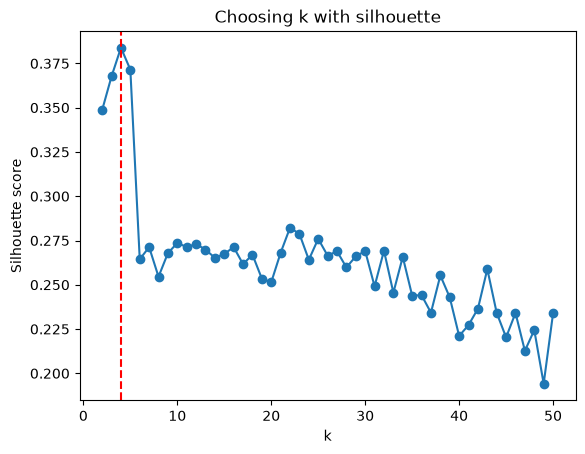

Best k: 4


In [8]:
K_RANGE = range(2, 51)

def choose_k(X, seed):
    scores = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(X)
        scores.append(silhouette_score(X, km.labels_, random_state=seed))
    return list(K_RANGE)[int(np.argmax(scores))], scores

k_best, sil_scores = choose_k(X, seed=0)

plt.plot(list(K_RANGE), sil_scores, marker="o")
plt.axvline(k_best, color="r", linestyle="--")
plt.xlabel("k"); plt.ylabel("Silhouette score"); plt.title("Choosing k with silhouette")
plt.show()
print("Best k:", k_best)

km = KMeans(n_clusters=k_best, n_init=10, random_state=0).fit(X)

### (b) Determine which family is the majority

In [9]:
def cluster_majority_labels(cluster_ids, Y):
    """cluster -> (majority family, genus, species) as encoded ints."""
    return {c: tuple(Counter(Y[cluster_ids == c, j]).most_common(1)[0][0]
                     for j in range(Y.shape[1]))
            for c in np.unique(cluster_ids)}

maj = cluster_majority_labels(km.labels_, Y)

summary = pd.DataFrame([
    {"cluster": c,
     "size": int((km.labels_ == c).sum()),
     "Family": encoders["Family"].inverse_transform([f])[0],
     "Genus": encoders["Genus"].inverse_transform([g])[0],
     "Species": encoders["Species"].inverse_transform([s])[0]}
    for c, (f, g, s) in maj.items()
])
print(summary.to_string(index=False))

 cluster  size          Family     Genus                Species
       0  3568 Leptodactylidae Adenomera AdenomeraHylaedactylus
       1  1982         Hylidae Hypsiboas      HypsiboasCordobae
       2  1031   Dendrobatidae  Ameerega     Ameeregatrivittata
       3   614         Hylidae Hypsiboas   HypsiboasCinerascens


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [10]:
n_runs = 50
dist_list, score_list, loss_list, k_list = [], [], [], []

for run in range(n_runs):
    k, _ = choose_k(X, seed=run)
    km_r = KMeans(n_clusters=k, n_init=10, random_state=run).fit(X)
    maj_r = cluster_majority_labels(km_r.labels_, Y)
    Y_pred = np.array([maj_r[c] for c in km_r.labels_])
    m = multilabel_metrics(Y, Y_pred)
    dist_list.append(m["hamming_distance"])
    score_list.append(m["hamming_score"])
    loss_list.append(m["hamming_loss"])
    k_list.append(k)
    print(f"run {run+1}: k={k}, distance={m['hamming_distance']:.4f}")

print(f"Hamming distance: mean={np.mean(dist_list):.4f}, std={np.std(dist_list):.4f}")
print(f"Hamming score:    mean={np.mean(score_list):.4f}, std={np.std(score_list):.4f}")
print(f"Hamming loss:     mean={np.mean(loss_list):.4f}, std={np.std(loss_list):.4f}")
print(f"Chosen k: mean={np.mean(k_list):.1f}, range={min(k_list)}-{max(k_list)}")

run 1: k=4, distance=0.6673
run 2: k=4, distance=0.6673
run 3: k=4, distance=0.7354
run 4: k=4, distance=0.6673
run 5: k=3, distance=0.8905
run 6: k=4, distance=0.6673
run 7: k=4, distance=0.6673
run 8: k=4, distance=0.6673
run 9: k=6, distance=0.5045
run 10: k=4, distance=0.6673
run 11: k=4, distance=0.6673
run 12: k=4, distance=0.6657
run 13: k=4, distance=0.6674
run 14: k=4, distance=0.6673
run 15: k=4, distance=0.6673
run 16: k=4, distance=0.6673
run 17: k=4, distance=0.6673
run 18: k=6, distance=0.5045
run 19: k=4, distance=0.6673
run 20: k=4, distance=0.6657
run 21: k=4, distance=0.6673
run 22: k=4, distance=0.7358
run 23: k=4, distance=0.7012
run 24: k=4, distance=0.6673
run 25: k=4, distance=0.6653
run 26: k=4, distance=0.6673
run 27: k=4, distance=0.6673
run 28: k=4, distance=0.6674
run 29: k=4, distance=0.6673
run 30: k=4, distance=0.6673
run 31: k=6, distance=0.5048
run 32: k=4, distance=0.7358
run 33: k=4, distance=0.6674
run 34: k=4, distance=0.6673
run 35: k=4, distance=0

Over 50 Monte Carlo runs (k chosen by silhouette in each run; mean k = 4.2, range 3–6):

| Metric | Mean | Std |
|---|---|---|
| Hamming distance | 0.6612 | 0.0738 |
| Hamming score | 0.7796 | 0.0246 |
| Hamming loss | 0.2204 | 0.0246 |

Most runs (42 of 50) chose k = 4 and gave a Hamming distance of about 0.667. The runs that chose k = 5 or 6 had a lower distance (about 0.50), and the two runs that chose k = 3 had a higher one (about 0.89), so most of the variation across runs comes from which k the silhouette selected.

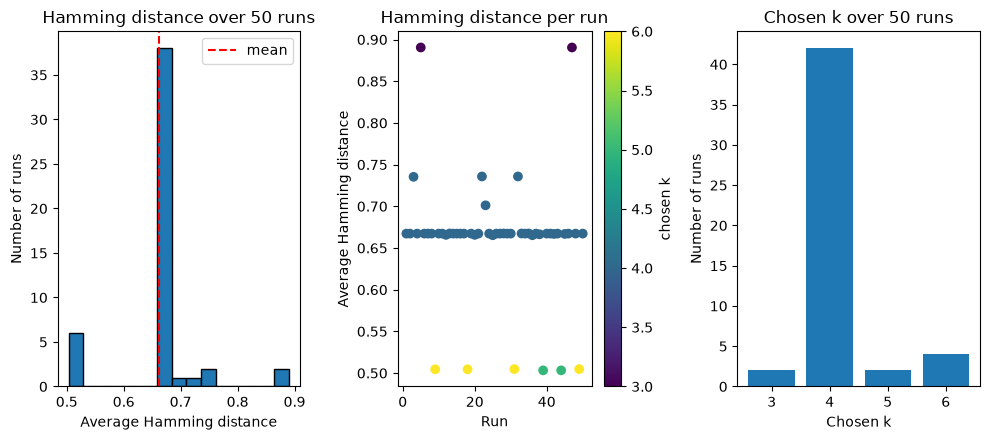

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4.5))

axes[0].hist(dist_list, bins=15, edgecolor="black")
axes[0].axvline(np.mean(dist_list), color="r", linestyle="--", label="mean")
axes[0].set_xlabel("Average Hamming distance")
axes[0].set_ylabel("Number of runs")
axes[0].set_title("Hamming distance over 50 runs")
axes[0].legend()

sc = axes[1].scatter(range(1, n_runs + 1), dist_list, c=k_list, cmap="viridis")
axes[1].set_xlabel("Run")
axes[1].set_ylabel("Average Hamming distance")
axes[1].set_title("Hamming distance per run")
fig.colorbar(sc, ax=axes[1], label="chosen k")

ks, counts = np.unique(k_list, return_counts=True)
axes[2].bar(ks, counts)
axes[2].set_xlabel("Chosen k")
axes[2].set_ylabel("Number of runs")
axes[2].set_title("Chosen k over 50 runs")
axes[2].set_xticks(ks)

plt.tight_layout()
plt.show()

## 3. ISLR 12.6.2

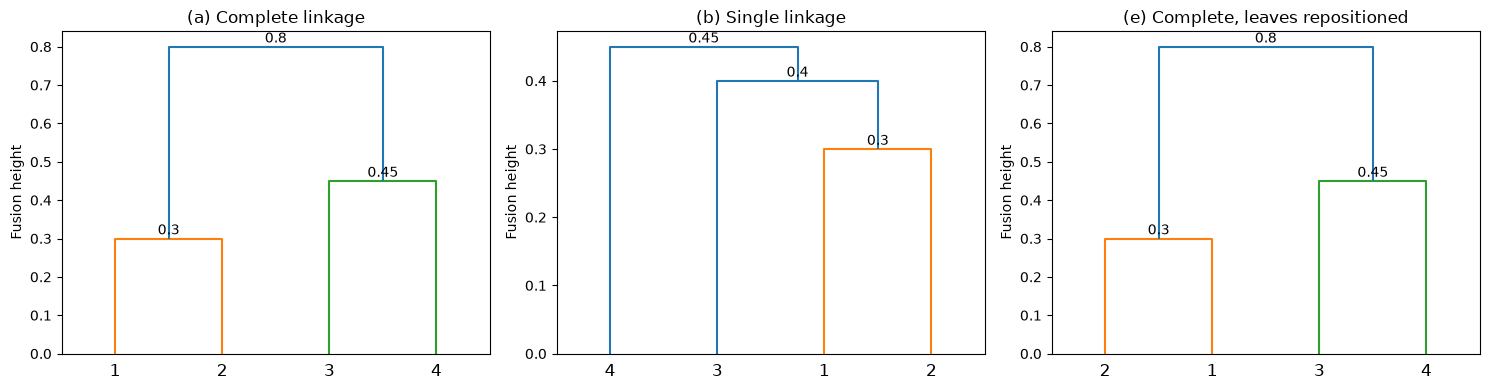

(c) complete [[1, 2], [3, 4]]
(d) single [[1, 2, 3], [4]]


In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

D = np.array([[0,   0.3, 0.4, 0.7],
              [0.3, 0,   0.5, 0.8],
              [0.4, 0.5, 0,   0.45],
              [0.7, 0.8, 0.45, 0]])
d = squareform(D)
labels = [1, 2, 3, 4]

Z_complete = linkage(d, method="complete")
Z_single = linkage(d, method="single")

Z_swapped = Z_complete.copy()
Z_swapped[0, [0, 1]] = Z_swapped[0, [1, 0]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, Z, title in zip(axes,
                        [Z_complete, Z_single, Z_swapped],
                        ["(a) Complete linkage", "(b) Single linkage", "(e) Complete, leaves repositioned"]):
    dn = dendrogram(Z, labels=labels, ax=ax)
    for ic, dc in zip(dn["icoord"], dn["dcoord"]):
        ax.annotate(f"{dc[1]:g}", (0.5 * (ic[1] + ic[2]), dc[1]),
                    textcoords="offset points", xytext=(0, 3), ha="center")
    ax.set_title(title)
    ax.set_ylabel("Fusion height")
plt.tight_layout()
plt.show()

for name, Z in [("(c) complete", Z_complete), ("(d) single", Z_single)]:
    cl = fcluster(Z, t=2, criterion="maxclust")
    print(name, [[labels[i] for i in range(4) if cl[i] == c] for c in sorted(set(cl))])

(e) is the same tree as (a) with the branches of the first fusion swapped; the clustering is unchanged.